# Decision Trees: A Fully Grown Regression Tree and Depth-Based Pruning of a Classification Tree
  A. A fully grown regression tree (squared-error splits) on a small two-feature dataset
  B. A Gini classification tree on a 2-D binary dataset: grown fully, then pruned to the depth
     after which the test-set sum of squared errors (SSE) stops changing

Run from this folder:  python decision_trees.py   (figures are written to ./figures)

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else "."
DATA = os.path.join(HERE, "data")
FIG = os.path.join(HERE, "figures")
os.makedirs(FIG, exist_ok=True)

BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#6b6b6b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## A. Fully grown regression tree

|--- x1 <= 4.50
|   |--- x2 <= 7.00
|   |   |--- x2 <= 5.50
|   |   |   |--- value: [10.00]
|   |   |--- x2 >  5.50
|   |   |   |--- value: [12.00]
|   |--- x2 >  7.00
|   |   |--- x1 <= 3.50
|   |   |   |--- value: [15.00]
|   |   |--- x1 >  3.50
|   |   |   |--- value: [18.00]
|--- x1 >  4.50
|   |--- x2 <= 16.50
|   |   |--- x1 <= 5.50
|   |   |   |--- value: [21.00]
|   |   |--- x1 >  5.50
|   |   |   |--- value: [25.00]
|   |--- x2 >  16.50
|   |   |--- x1 <= 7.50
|   |   |   |--- value: [28.00]
|   |   |--- x1 >  7.50
|   |   |   |--- value: [30.00]

depth 3 | leaves 8 | training MSE 0.0

root split candidates on x1 (threshold -> total SSE):
  x1 <= 1.5: 271.43
  x1 <= 2.5: 172.83
  x1 <= 3.5: 109.87
  x1 <= 4.5: 82.75
  x1 <= 5.5: 91.47
  x1 <= 6.5: 160.83
  x1 <= 7.5: 265.71


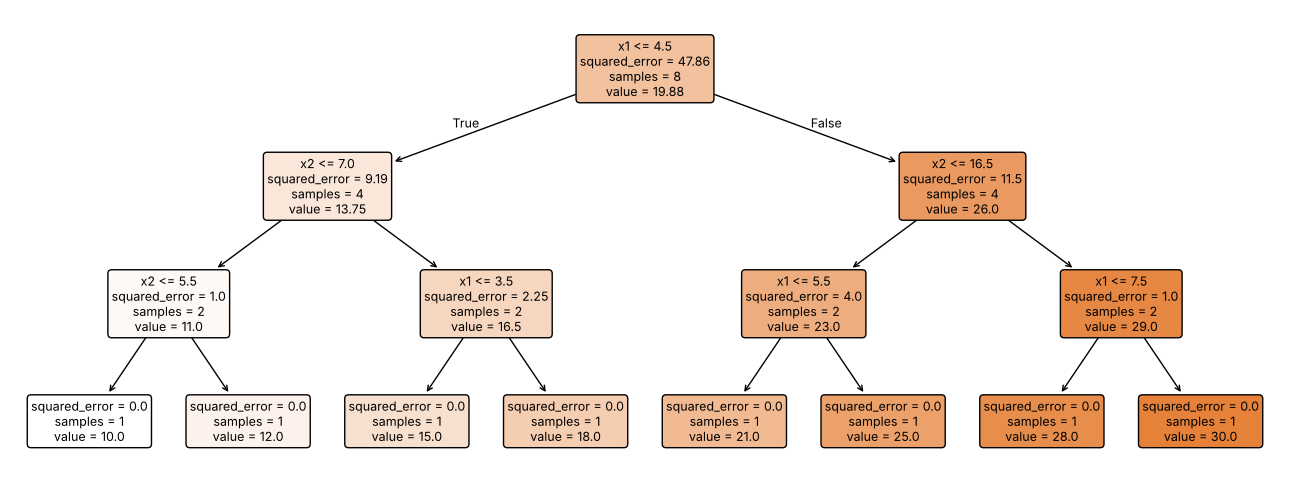

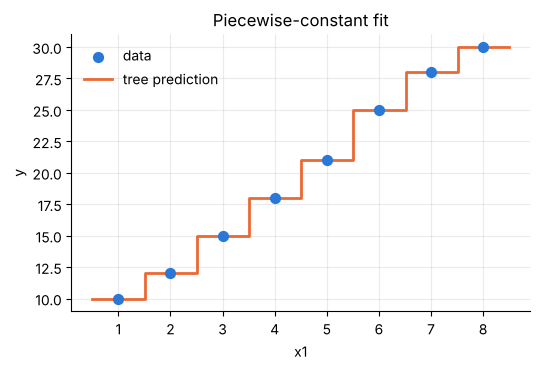

In [2]:
small = pd.DataFrame({"x1": [1, 2, 3, 4, 5, 6, 7, 8],
                      "x2": [5, 6, 8, 10, 12, 15, 18, 20],
                      "y": [10, 12, 15, 18, 21, 25, 28, 30]})
Xa, ya = small[["x1", "x2"]].values, small["y"].values
reg = DecisionTreeRegressor(criterion="squared_error", random_state=42).fit(Xa, ya)
print(export_text(reg, feature_names=["x1", "x2"]))
print("depth", reg.get_depth(), "| leaves", reg.get_n_leaves(),
      "| training MSE", mean_squared_error(ya, reg.predict(Xa)))

# SSE of every candidate first split on x1 (what the root split minimises)
print("\nroot split candidates on x1 (threshold -> total SSE):")
for t in np.arange(1.5, 8, 1.0):
    left, right = ya[Xa[:, 0] <= t], ya[Xa[:, 0] > t]
    sse = ((left - left.mean()) ** 2).sum() + ((right - right.mean()) ** 2).sum()
    print(f"  x1 <= {t}: {sse:.2f}")

fig, ax = plt.subplots(figsize=(13, 5))
plot_tree(reg, feature_names=["x1", "x2"], filled=True, rounded=True, fontsize=9, precision=2, ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "regression_tree.png"), dpi=160)
plt.show()

xg = np.linspace(0.5, 8.5, 400)
x2_of_x1 = np.interp(xg, small["x1"], small["x2"])          # follow the data's own x1-x2 relation
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.scatter(small["x1"], ya, color=BLUE, s=50, zorder=3, label="data")
ax.step(xg, reg.predict(np.c_[xg, x2_of_x1]), where="post", color=ORANGE, lw=2, label="tree prediction")
ax.set(xlabel="x1", ylabel="y", title="Piecewise-constant fit")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "regression_tree_fit.png"), dpi=160)
plt.show()

## B. Classification tree and depth pruning


train 210 (class 1 share 0.51) | test 90 (class 1 share 0.48)
full tree: depth 6, leaves 16, train acc 1.0000, test acc 0.9556
 depth    sse  leaves  train_acc  test_acc  delta_sse
     1 8.2636       2     0.9381    0.9000        NaN
     2 6.4971       4     0.9381    0.9000     1.7665
     3 3.8338       8     0.9714    0.9556     2.6633
     4 3.8379      13     0.9905    0.9556     0.0041
     5 3.6400      15     0.9952    0.9556     0.1979
     6 4.0000      16     1.0000    0.9556     0.3600

smallest |ΔSSE| between depth 3 and 4 -> prune at depth 3
pruned tree: depth 3, leaves 8, train acc 0.9714, test acc 0.9556


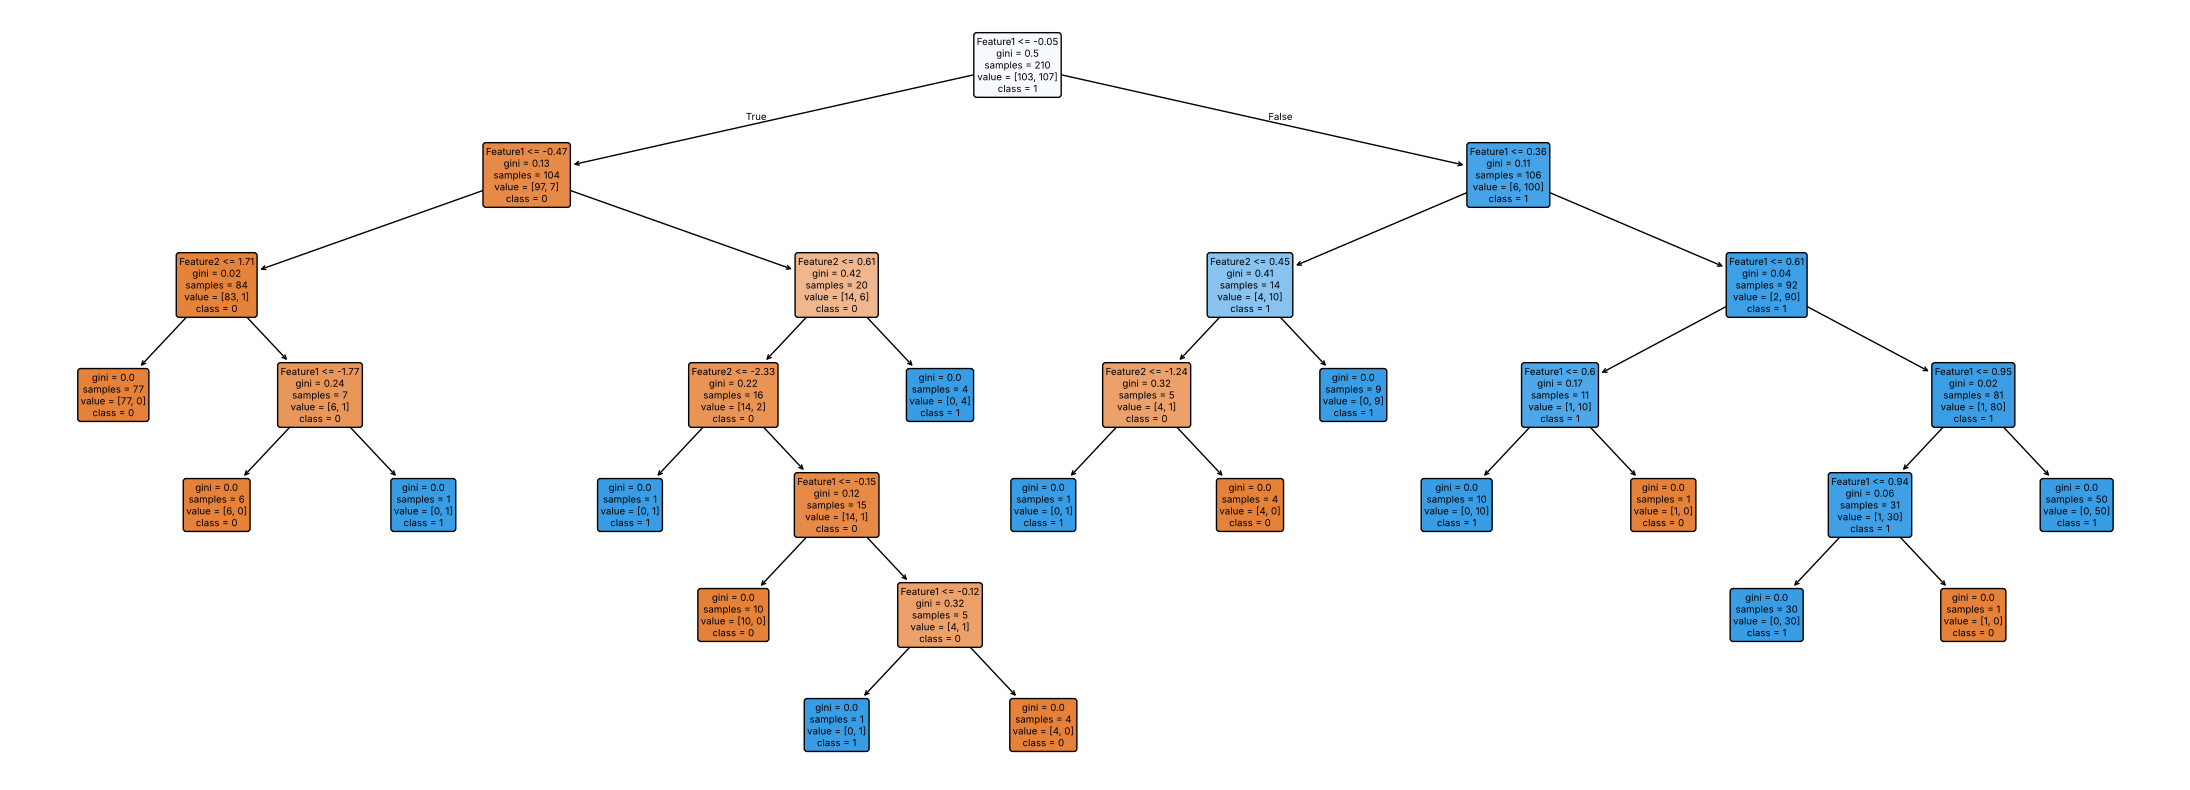

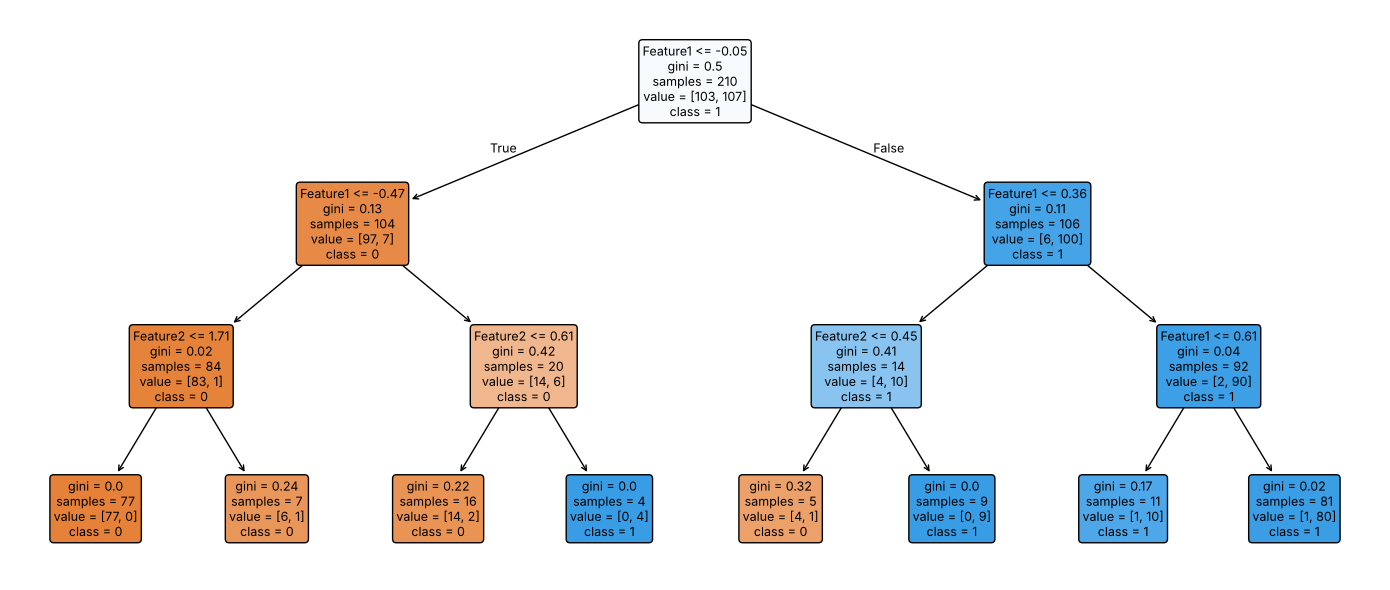

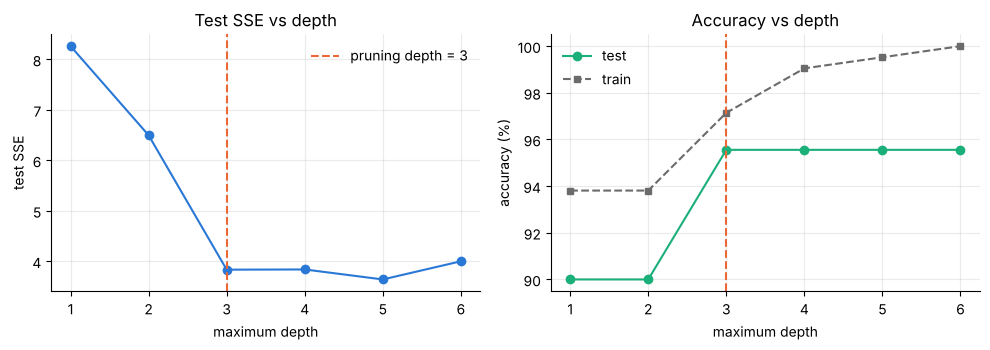

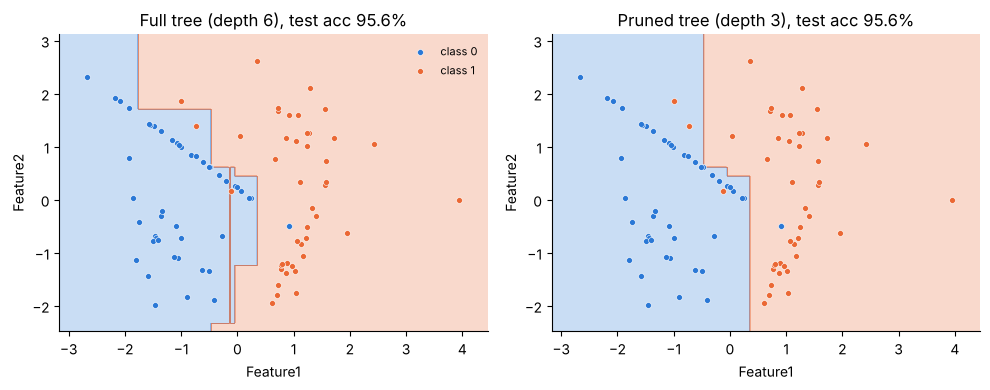

In [3]:
tr = pd.read_csv(os.path.join(DATA, "tree_train.csv"))
te = pd.read_csv(os.path.join(DATA, "tree_test.csv"))
F = ["Feature1", "Feature2"]
Xtr, ytr = tr[F].values, tr["Label"].values.astype(int)
Xte, yte = te[F].values, te["Label"].values.astype(int)
print(f"\ntrain {len(ytr)} (class 1 share {ytr.mean():.2f}) | test {len(yte)} (class 1 share {yte.mean():.2f})")

full = DecisionTreeClassifier(criterion="gini", random_state=42).fit(Xtr, ytr)
D = full.get_depth()
print(f"full tree: depth {D}, leaves {full.get_n_leaves()}, "
      f"train acc {full.score(Xtr, ytr):.4f}, test acc {full.score(Xte, yte):.4f}")

rows = []
for d in range(1, D + 1):
    m = DecisionTreeClassifier(criterion="gini", max_depth=d, random_state=42).fit(Xtr, ytr)
    p1 = m.predict_proba(Xte)[:, 1]
    rows.append(dict(depth=d, sse=float(np.sum((p1 - yte) ** 2)), leaves=m.get_n_leaves(),
                     train_acc=m.score(Xtr, ytr), test_acc=m.score(Xte, yte)))
res = pd.DataFrame(rows)
res["delta_sse"] = res["sse"].diff().abs()
print(res.round(4).to_string(index=False))

# The smallest |ΔSSE| is between depth k-1 and k: growing to depth k adds nothing, so prune at k-1.
k = int(res.loc[res["delta_sse"].idxmin(), "depth"])
PRUNE_DEPTH = k - 1
print(f"\nsmallest |ΔSSE| between depth {k - 1} and {k} -> prune at depth {PRUNE_DEPTH}")
pruned = DecisionTreeClassifier(criterion="gini", max_depth=PRUNE_DEPTH, random_state=42).fit(Xtr, ytr)
print(f"pruned tree: depth {pruned.get_depth()}, leaves {pruned.get_n_leaves()}, "
      f"train acc {pruned.score(Xtr, ytr):.4f}, test acc {pruned.score(Xte, yte):.4f}")

fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(full, feature_names=F, class_names=["0", "1"], filled=True, rounded=True, fontsize=7,
          precision=2, ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "classification_tree_full.png"), dpi=140)
plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(pruned, feature_names=F, class_names=["0", "1"], filled=True, rounded=True, fontsize=9,
          precision=2, ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "classification_tree_pruned.png"), dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(res["depth"], res["sse"], "o-", color=BLUE, ms=6)
axes[0].axvline(PRUNE_DEPTH, color=ORANGE, ls="--", lw=1.5, label=f"pruning depth = {PRUNE_DEPTH}")
axes[0].set(xlabel="maximum depth", ylabel="test SSE", title="Test SSE vs depth")
axes[0].legend(frameon=False)
axes[1].plot(res["depth"], res["test_acc"] * 100, "o-", color=GREEN, ms=6, label="test")
axes[1].plot(res["depth"], res["train_acc"] * 100, "s--", color=GREY, ms=5, label="train")
axes[1].axvline(PRUNE_DEPTH, color=ORANGE, ls="--", lw=1.5)
axes[1].set(xlabel="maximum depth", ylabel="accuracy (%)", title="Accuracy vs depth")
axes[1].legend(frameon=False)
for a in axes:
    a.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "sse_vs_depth.png"), dpi=160)
plt.show()


def boundary(ax, clf, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 400),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 400))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap=ListedColormap([BLUE, ORANGE]))
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=18, color=BLUE, edgecolors="white", lw=0.4, label="class 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=18, color=ORANGE, edgecolors="white", lw=0.4, label="class 1")
    ax.set(title=title, xlabel="Feature1", ylabel="Feature2")


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
boundary(axes[0], full, Xte, yte, f"Full tree (depth {D}), test acc {full.score(Xte, yte) * 100:.1f}%")
boundary(axes[1], pruned, Xte, yte,
         f"Pruned tree (depth {PRUNE_DEPTH}), test acc {pruned.score(Xte, yte) * 100:.1f}%")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "decision_boundaries.png"), dpi=160)
plt.show()